# 04. Inference & Model Interpretation

## Overview
This notebook demonstrates **inference in the wild**. We will:
1.  Load our trained model (EfficientNet-B3 or ResNet50).
2.  Process a new image (simulating a real-world clinical scenario).
3.  Predict the Diabetic Retinopathy grade and confidence.
4.  Apply **Grad-CAM** (Gradient-weighted Class Activation Mapping) to visualize *where* the model is looking.

## Objectives
-   Showcase the end-to-end usage of the model.
-   Provide "Explainable AI" visuals to build trust in the model's decisions.

In [6]:
# --- Imports ---
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

# Add project root to path
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import MODELS_DIR, PROCESSED_DATA_DIR
from src.data.preprocessing import ImagePreprocessor
from src.models.explainability import GradCAM, get_target_layer
from src.models.inference import predict_and_visualize
from src.models.model import DRModel
from src.visualization.eda import test_api_and_visualize
from src.visualization.plots import set_plot_style

# --- Configuration ---
set_plot_style()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device: cuda


In [7]:
# 2. Load Model
# --------------------------------------------------------------------------
# Select model to use for inference
MODEL_NAME = "efficientnet_b3"  # or "resnet50"
# --------------------------------------------------------------------------

print(f"Loading {MODEL_NAME}...")

# Initialize architecture
model = DRModel(model_name=MODEL_NAME, num_classes=5, pretrained=False)

# Load weights
weights_path = MODELS_DIR / f"{MODEL_NAME}_best.pth"
if weights_path.exists():
    model.load_state_dict(torch.load(weights_path, map_location=device))
    print("Weights loaded successfully.")
else:
    raise FileNotFoundError(f"Weights not found at {weights_path}")

model.to(device)
model.eval()
print("Model ready for inference.")

# Initialize Preprocessor (Must match training settings)
preprocessor = ImagePreprocessor(target_size=(512, 512), sigmaX=30)

Loading efficientnet_b3...
Weights loaded successfully.
Model ready for inference.


In [8]:
# 3. Setup Inference Pipeline

# Initialize Grad-CAM
target_layer = get_target_layer(model, MODEL_NAME)
grad_cam = GradCAM(model, target_layer)
print(f"Grad-CAM hooked into: {target_layer}")


# Define a lightweight wrapper that injects notebook-scoped model state
def run_inference_and_visualize(image_path_or_url, true_label=None, eye_side="left", patient_info=None):
    """Wrapper around predict_and_visualize with notebook globals."""
    predict_and_visualize(
        image_path_or_url=image_path_or_url,
        model=model,
        preprocessor=preprocessor,
        grad_cam=grad_cam,
        device=device,
        eye_side=eye_side,
        true_label=true_label,
        patient_info=patient_info,
        save_folder="inference_demo",
    )
    plt.show()

Grad-CAM hooked into: Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


Selected 5 examples for demonstration.
2026-02-17 11:19:23,838 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_no_dr_0.63_74.png
2026-02-17 11:19:23,838 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_no_dr_0.63_74.png


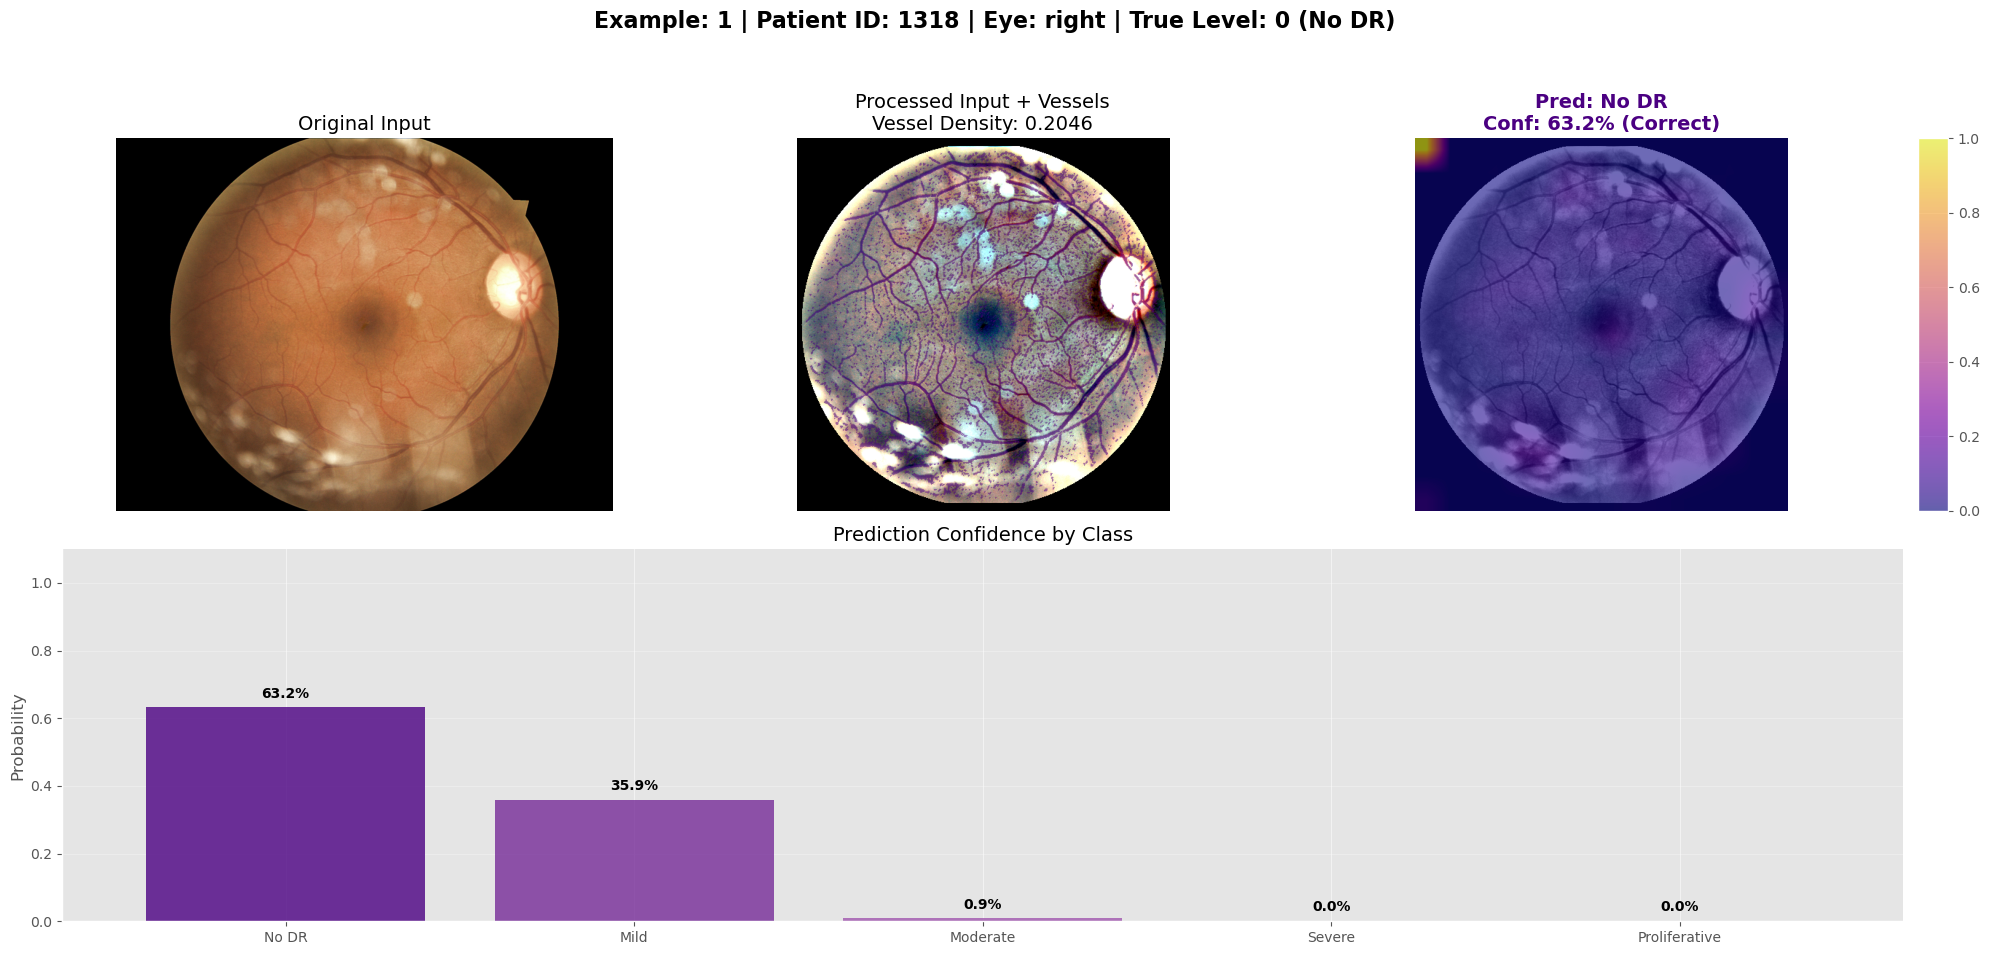




2026-02-17 11:19:26,037 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_mild_0.63_274.png
2026-02-17 11:19:26,037 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_mild_0.63_274.png


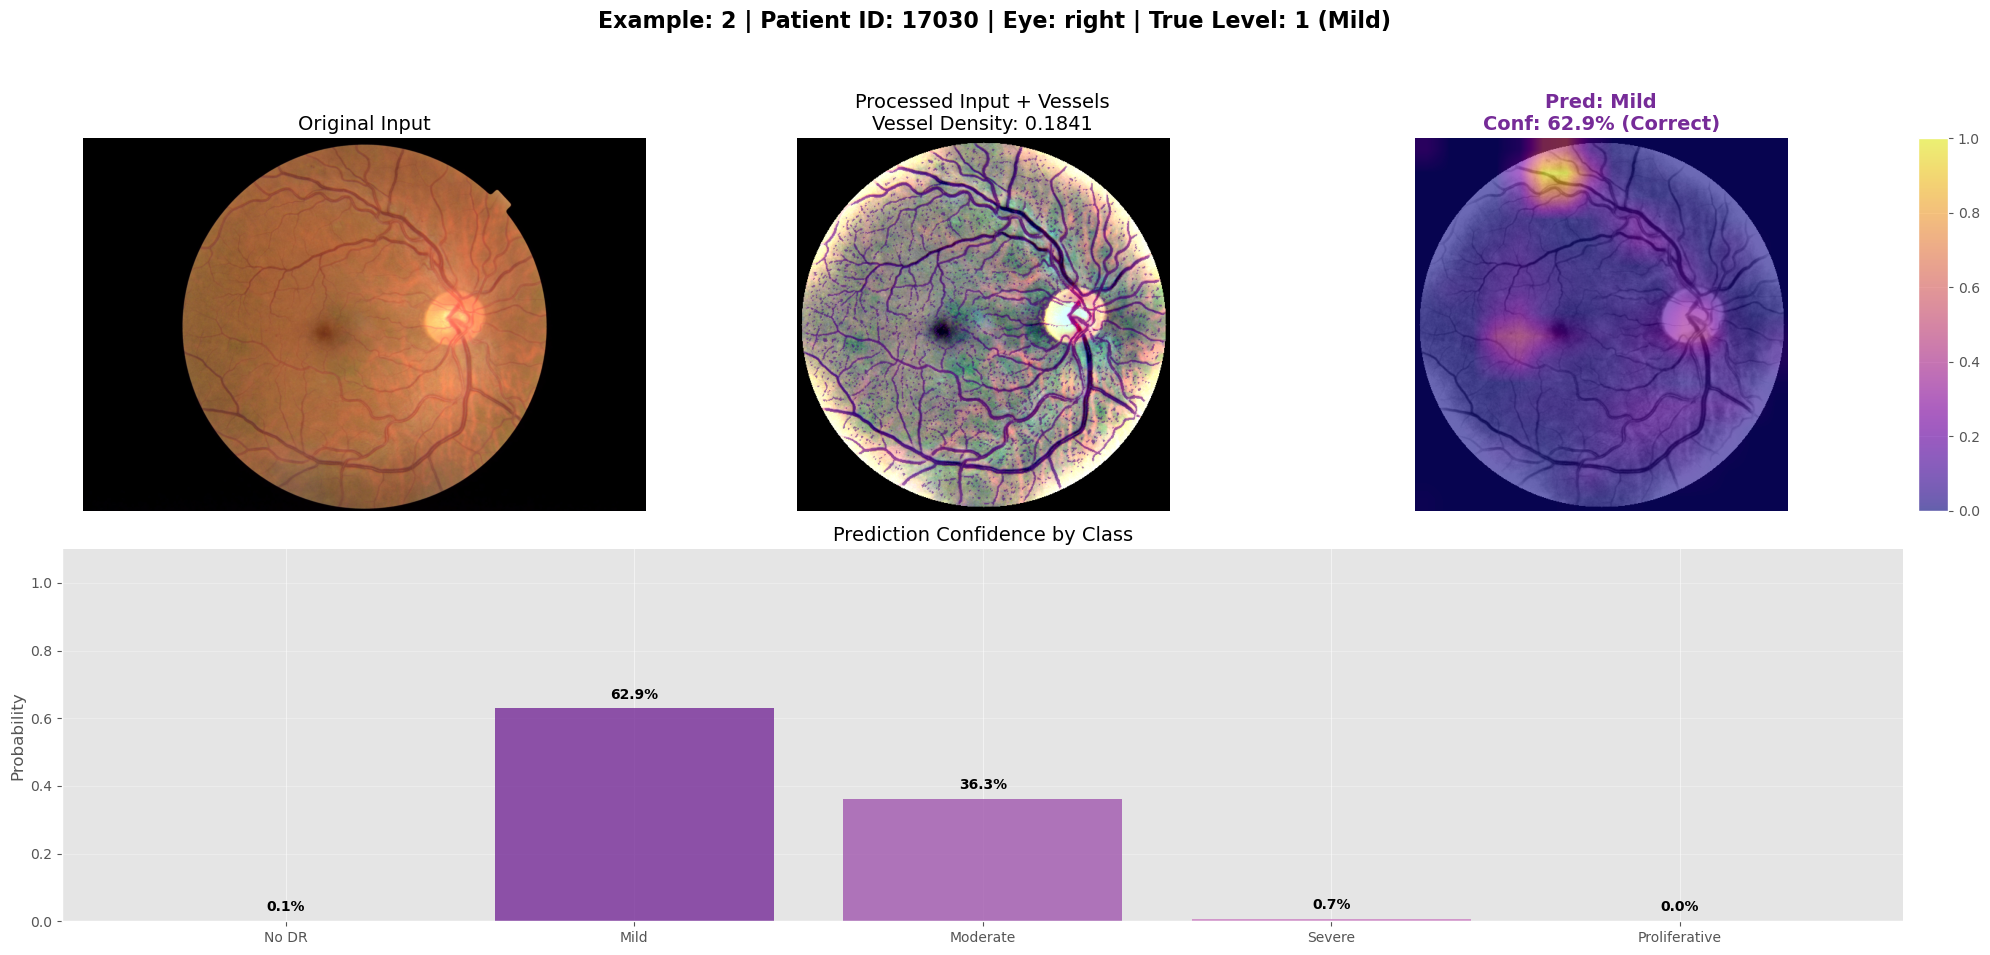




2026-02-17 11:19:28,400 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_mild_0.54_41.png
2026-02-17 11:19:28,400 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_mild_0.54_41.png


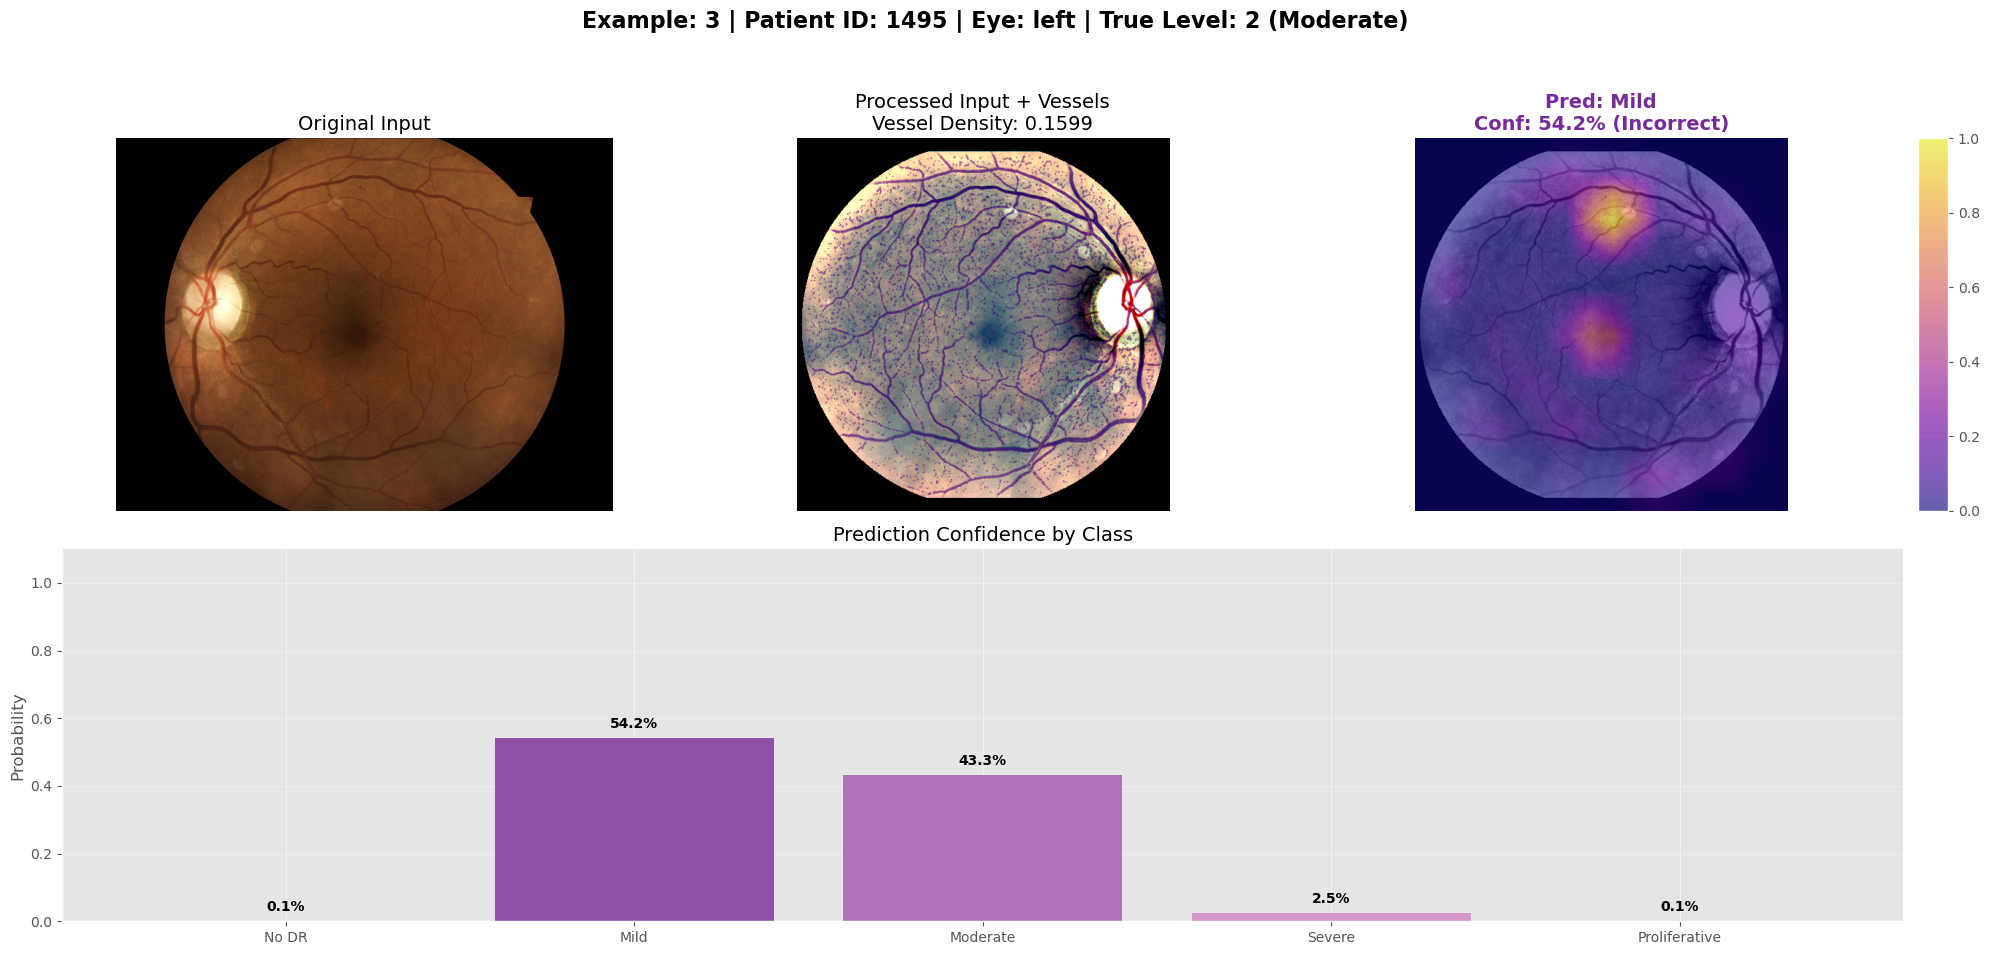




2026-02-17 11:19:30,632 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_moderate_0.61_729.png
2026-02-17 11:19:30,632 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_moderate_0.61_729.png


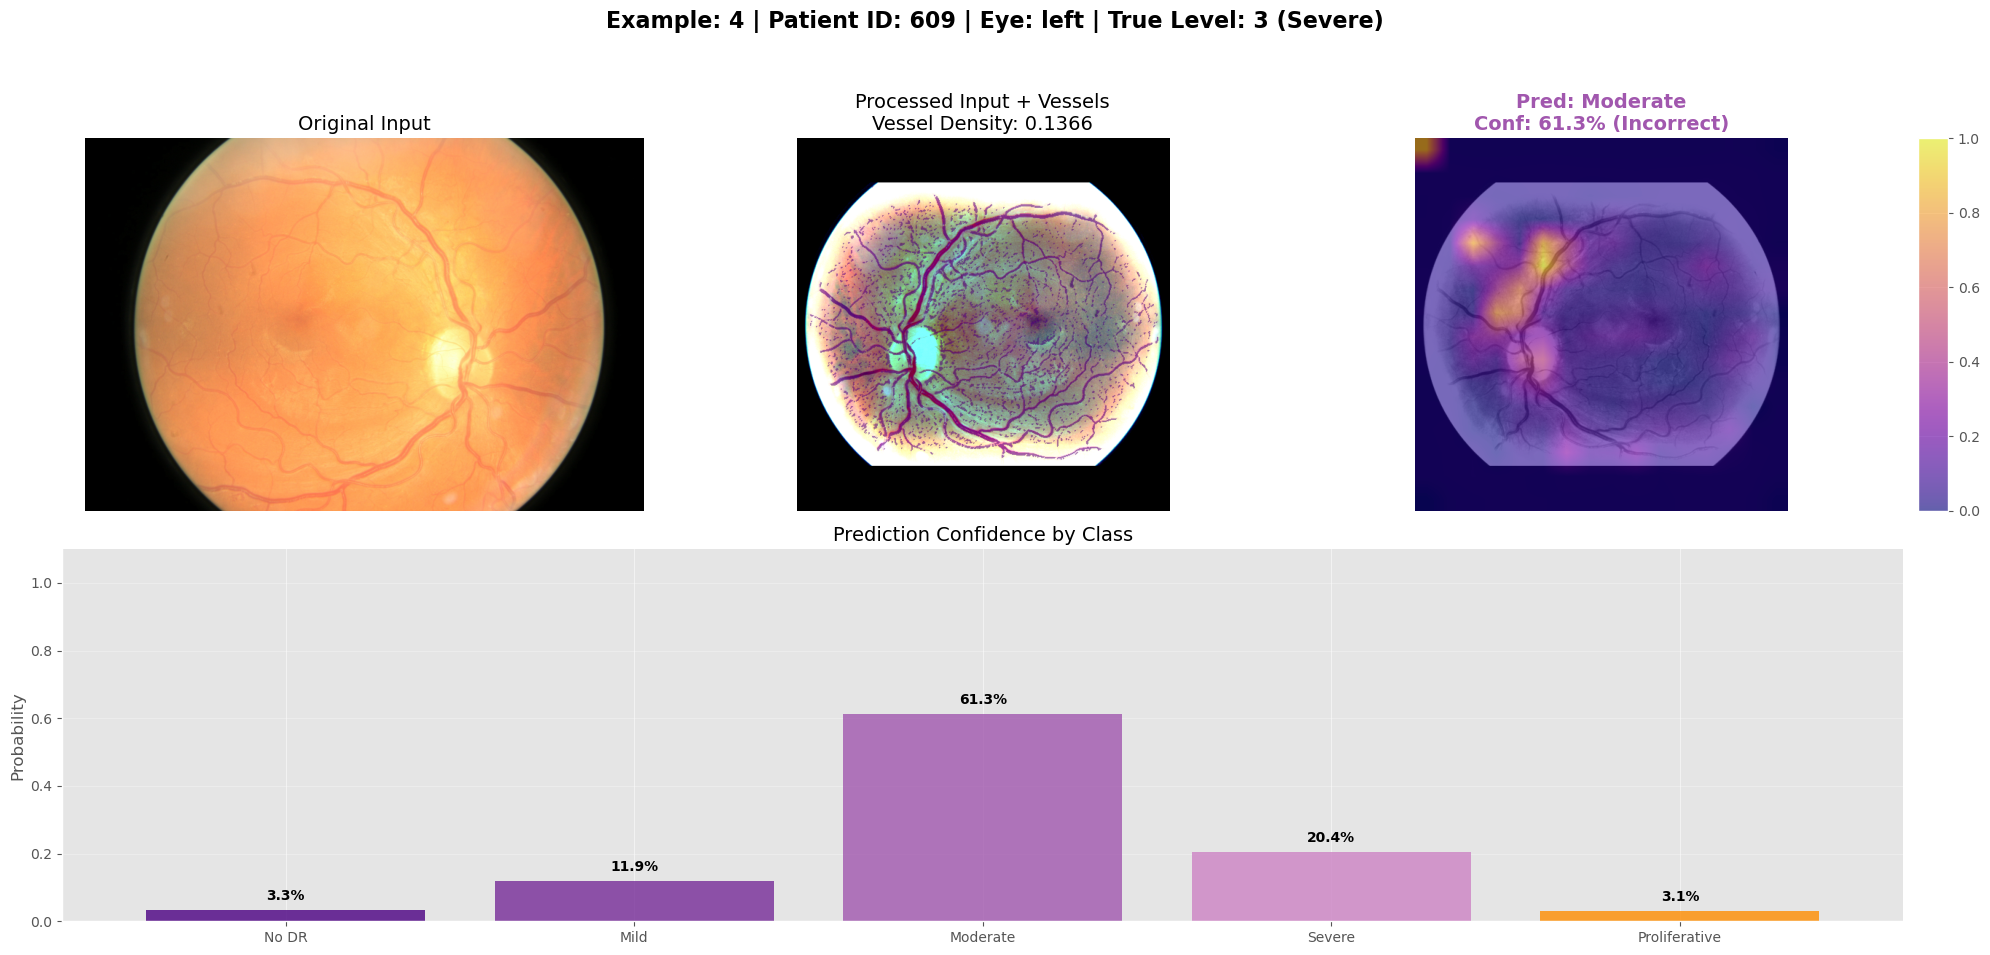




2026-02-17 11:19:32,595 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_moderate_0.50_806.png
2026-02-17 11:19:32,595 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\inference_demo\inference_moderate_0.50_806.png


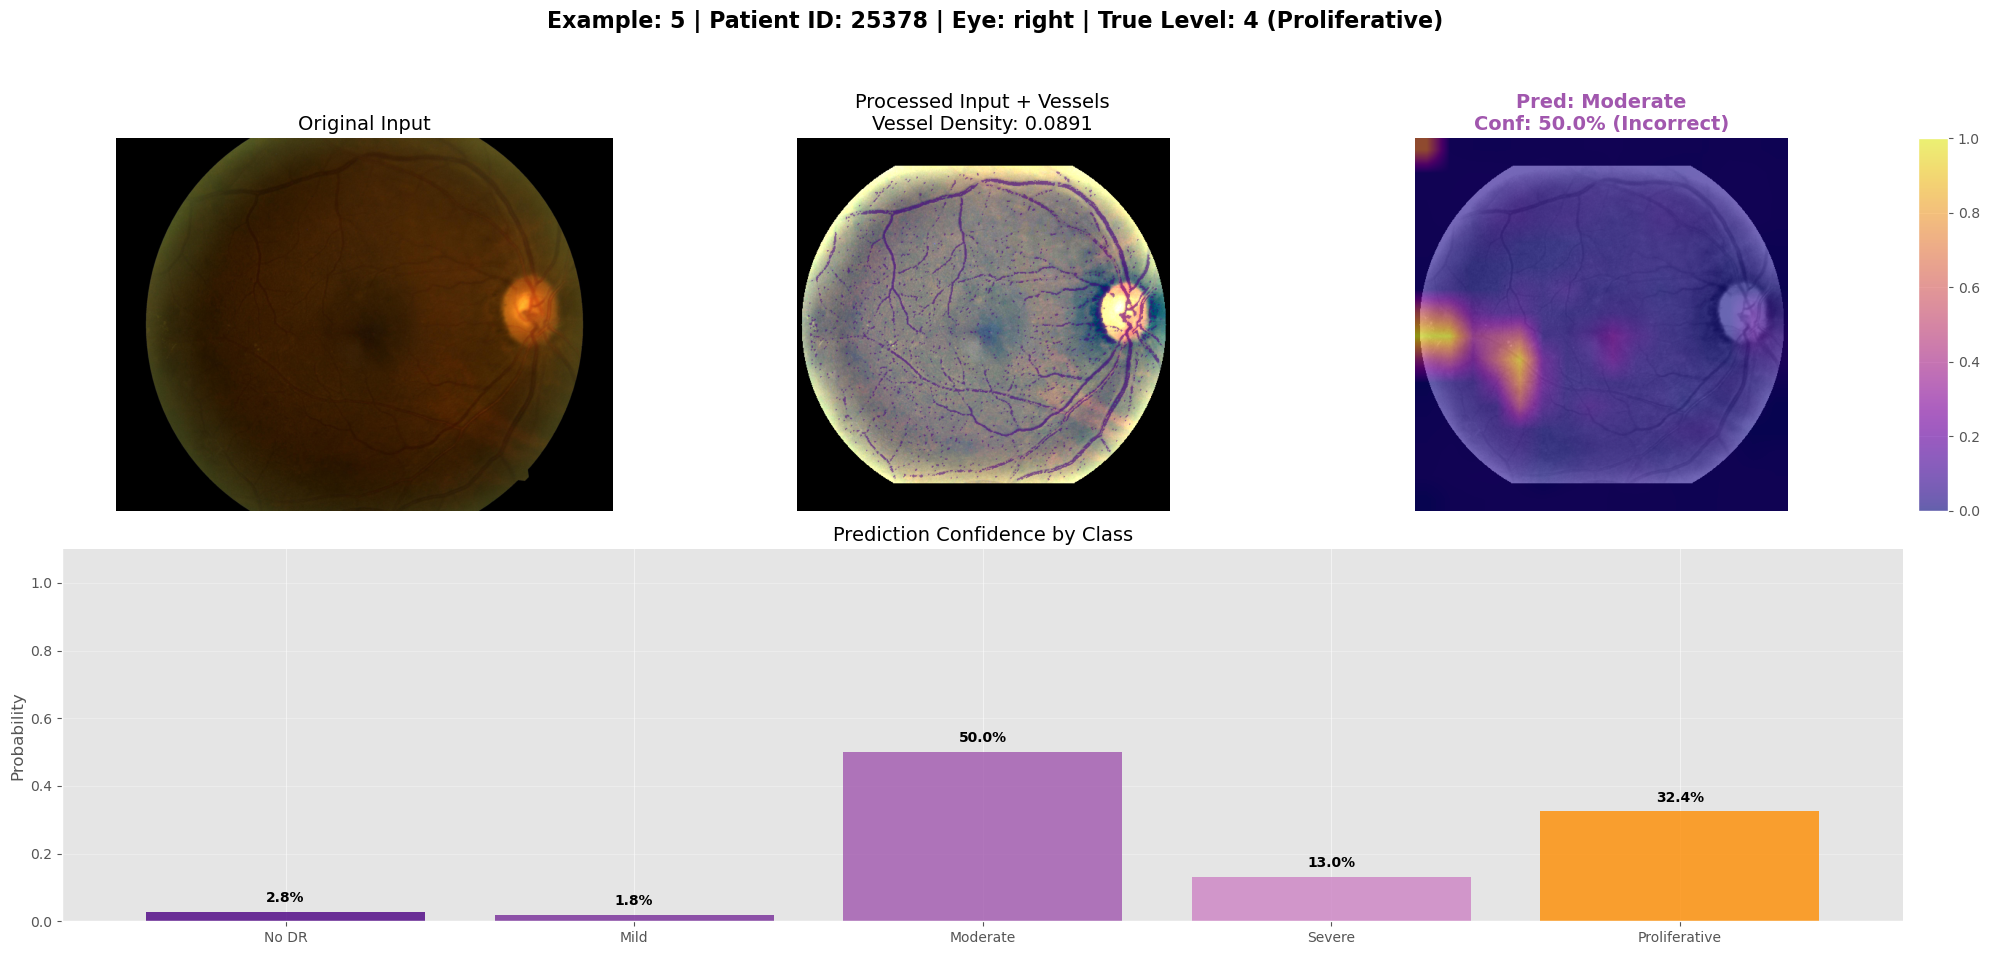

In [9]:
# 4. Run Inference on Multiple Examples

manifest_path = PROCESSED_DATA_DIR / "manifest.csv"
if manifest_path.exists():
    df = pd.read_csv(manifest_path)

    # Select one example from each class if available
    samples = []
    classes = [0, 1, 2, 3, 4]

    for c in classes:
        class_samples = df[df["level"] == c]
        if not class_samples.empty:
            samples.append(class_samples.sample(1).iloc[0])

    print(f"Selected {len(samples)} examples for demonstration.")

    class_map = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}

    # Display all selected samples
    for i, sample in enumerate(samples):
        # Prepare Info for Suptitle
        info = {
            "Example": i + 1,
            "Patient ID": sample["patient_id"],
            "Eye": sample["eye"],
            "True Level": f"{sample['level']} ({class_map[sample['level']]})",
        }

        try:
            run_inference_and_visualize(
                sample["path"],
                true_label=class_map[sample["level"]],
                eye_side=sample["eye"],  # Pass explicitly
                patient_info=info,
            )
        except Exception as e:
            print(f"Error processing image {sample['path']}: {e}")

        # Add some spacing between examples
        print("\n" * 2)

else:
    print("No manifest found.")

# 5. Production API Verification

Finally, we test the **FastAPI** serving layer directly within the notebook using `TestClient`. 
This simulates a real HTTP request to the deployed service (API) and verifies:
1.  Image upload via `multipart/form-data`.
2.  End-to-end inference execution.
3.  Response schema validation (Diagnosis + Confidence + Grad-CAM overlay).

2026-02-17 11:19:33,054 - src.app.main - INFO - Loading DR Detection Model...
2026-02-17 11:19:33,054 - src.app.main - INFO - Loading DR Detection Model...
2026-02-17 11:19:33,054 - src.app.predictor - INFO - Initializing Predictor on cuda...
2026-02-17 11:19:33,054 - src.app.predictor - INFO - Initializing Predictor on cuda...
2026-02-17 11:19:33,147 - src.app.predictor - INFO - Loading weights from C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\models\efficientnet_b3_best.pth
2026-02-17 11:19:33,147 - src.app.predictor - INFO - Loading weights from C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\models\efficientnet_b3_best.pth
2026-02-17 11:19:33,428 - src.app.predictor - INFO - Grad-CAM initialized on layer: Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)
2026-

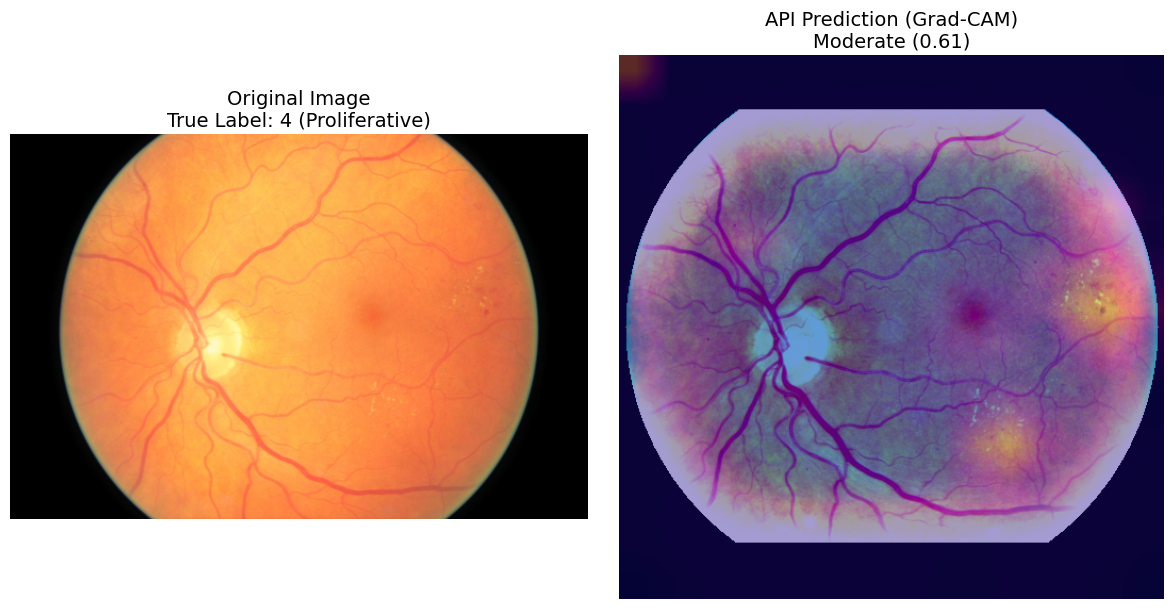

2026-02-17 11:19:34,617 - src.app.main - INFO - Model unloaded.
2026-02-17 11:19:34,617 - src.app.main - INFO - Model unloaded.


In [10]:
# 5. Production API Verification
from fastapi.testclient import TestClient

from src.app.main import app, models

try:
    with TestClient(app) as client:
        print("TestClient initialized and lifespan started.")

        if "predictor" in models:
            print("Model loaded successfully in app state.")
        else:
            print("WARNING: Model NOT found in app state after startup.")

        test_api_and_visualize(client, PROCESSED_DATA_DIR / "manifest.csv")

except Exception as e:
    print(f"TestClient failed to start: {e}")